# Customer Segmentation Using Data Science

## Project Overview

This project performs **customer segmentation using K-Means clustering**. The objective is to analyze customer demographics and purchasing behavior, group similar customers into meaningful segments, visualize the clusters, and derive business insights for targeted marketing.

### Internship Requirements Covered
- Load and analyze the customer dataset
- Perform data preprocessing and cleaning
- Apply K-Means clustering
- Determine a suitable number of clusters using the Elbow Method
- Visualize customer clusters
- Interpret cluster characteristics
- Generate business insights and final outputs

**Dataset:** Mall Customers Dataset  
**Primary clustering features:** Annual Income (k$) and Spending Score (1-100)


## 1. Import Required Libraries

We use:
- **Pandas** for data loading and analysis
- **NumPy** for numerical operations
- **Matplotlib** and **Seaborn** for visualization
- **Scikit-learn** for K-Means clustering and evaluation


In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Define Project Paths

The notebook is stored inside `notebooks/`, so the raw dataset is expected at:

`../data/raw/Mall_Customers.csv`

The notebook also creates an output directory for charts and processed results.


In [2]:
DATA_PATH = "../data/raw/Mall_Customers.csv"
PROCESSED_DIR = "../data/processed"
OUTPUT_DIR = "../outputs"

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}\n"
        "Please place Mall_Customers.csv inside data/raw/"
    )

print("Dataset path:", DATA_PATH)
print("Output directory:", OUTPUT_DIR)


Dataset path: ../data/raw/Mall_Customers.csv
Output directory: ../outputs


## 3. Load the Dataset

Load the Mall Customers CSV file using Pandas and display the first records.


In [3]:
df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully.")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

display(df.head(10))


Dataset loaded successfully.
Rows: 200
Columns: 5


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


## 4. Dataset Overview

Let's inspect the structure, data types, descriptive statistics, and missing values.


In [4]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes.to_frame("Data Type"))

print("\nDataset Information:")
df.info()


Dataset Shape: (200, 5)

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Data Types:


,Data Type
CustomerID,int64
Gender,str
Age,int64
Annual Income (k$),int64
Spending Score (1-100),int64



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [5]:
print("Descriptive Statistics:")
display(df.describe(include="all").T)

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Rows:", df.duplicated().sum())


Descriptive Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.00,NaN,NaN,NaN,100.50,57.88,1.00,50.75,100.50,150.25,200.00
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.00,NaN,NaN,NaN,38.85,13.97,18.00,28.75,36.00,49.00,70.00
Annual Income (k$),200.00,NaN,NaN,NaN,60.56,26.26,15.00,41.50,61.50,78.00,137.00
Spending Score (1-100),200.00,NaN,NaN,NaN,50.20,25.82,1.00,34.75,50.00,73.00,99.00



Missing Values:


,Missing Values
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0



Duplicate Rows: 0


## 5. Data Cleaning and Preprocessing

Before clustering, we:
1. Remove duplicate records if any exist.
2. Standardize column names for easier Python usage.
3. Check for missing values.
4. Remove `CustomerID` from clustering features because it is only an identifier.
5. Keep the original customer-level information for interpretation.


In [6]:
# Work on a copy
df_clean = df.copy()

# Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace("-", "_")
)

print("Standardized columns:")
print(df_clean.columns.tolist())

# Remove duplicate rows
duplicate_count = df_clean.duplicated().sum()
if duplicate_count > 0:
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print(f"Duplicate rows removed: {duplicate_count}")
print(f"Cleaned dataset shape: {df_clean.shape}")


Standardized columns:
['customerid', 'gender', 'age', 'annual_income_k$', 'spending_score_1_100']
Duplicate rows removed: 0
Cleaned dataset shape: (200, 5)


In [7]:
# Verify missing values after cleaning
missing_values = df_clean.isnull().sum()

print("Missing values after cleaning:")
display(missing_values.to_frame("Missing Values"))

# Validate required columns
required_columns = {
    "customerid",
    "gender",
    "age",
    "annual_income_k$",
    "spending_score_1_100"
}

missing_required = required_columns - set(df_clean.columns)

if missing_required:
    raise ValueError(
        f"Required columns are missing: {missing_required}\n"
        f"Available columns: {df_clean.columns.tolist()}"
    )

print("Required columns are available.")


Missing values after cleaning:


,Missing Values
customerid,0
gender,0
age,0
annual_income_k$,0
spending_score_1_100,0


Required columns are available.


## 6. Exploratory Data Analysis

We examine customer demographics and purchasing behavior before clustering.


In [8]:
print("Gender Distribution:")
display(df_clean["gender"].value_counts())

print("Age Statistics:")
display(df_clean["age"].describe().to_frame("Age"))

print("Income Statistics:")
display(df_clean["annual_income_k$"].describe().to_frame("Annual Income (k$)"))

print("Spending Score Statistics:")
display(
    df_clean["spending_score_1_100"]
    .describe()
    .to_frame("Spending Score")
)


Gender Distribution:


gender
Female    112
Male       88
Name: count, dtype: int64

Age Statistics:


,Age
count,200.00
mean,38.85
std,13.97
min,18.00
25%,28.75
50%,36.00
75%,49.00
max,70.00


Income Statistics:


,Annual Income (k$)
count,200.00
mean,60.56
std,26.26
min,15.00
25%,41.50
50%,61.50
75%,78.00
max,137.00


Spending Score Statistics:


,Spending Score
count,200.00
mean,50.20
std,25.82
min,1.00
25%,34.75
50%,50.00
75%,73.00
max,99.00


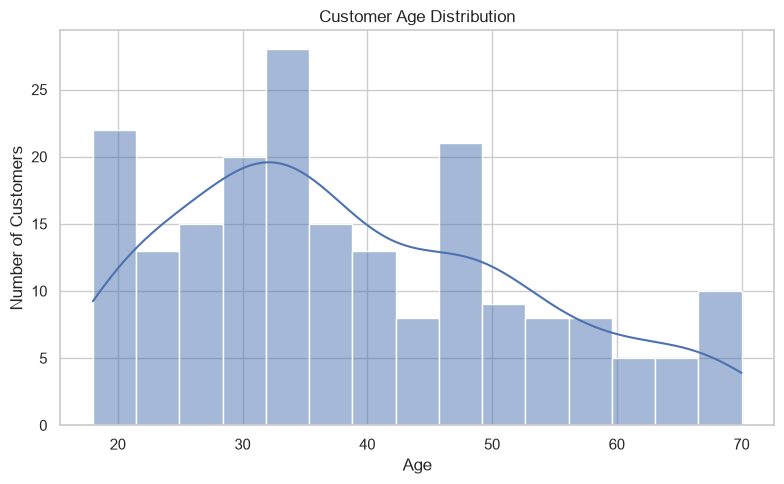

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["age"], bins=15, kde=True)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "age_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()


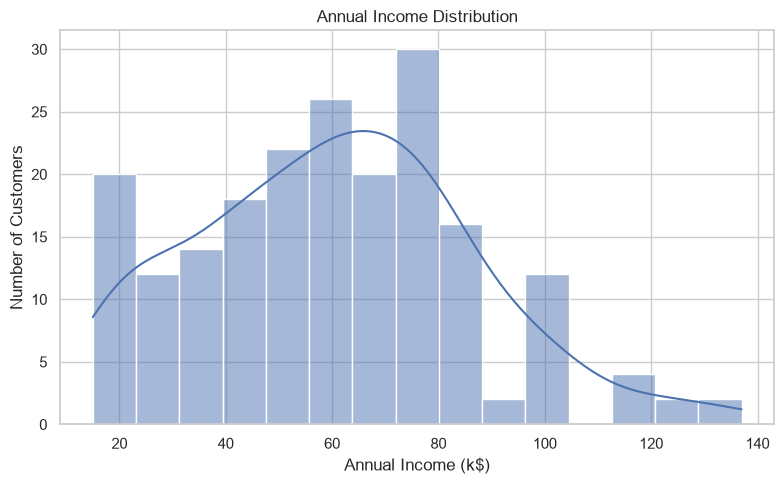

In [10]:
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["annual_income_k$"], bins=15, kde=True)
plt.title("Annual Income Distribution")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "income_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()


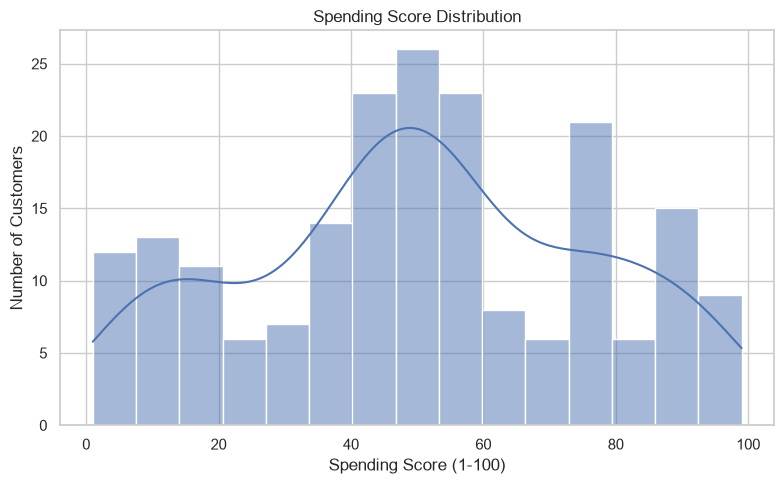

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["spending_score_1_100"], bins=15, kde=True)
plt.title("Spending Score Distribution")
plt.xlabel("Spending Score (1-100)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "spending_score_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()


## 7. Analyze Relationships Between Numerical Features

A correlation matrix helps us understand relationships between age, income, and spending score.


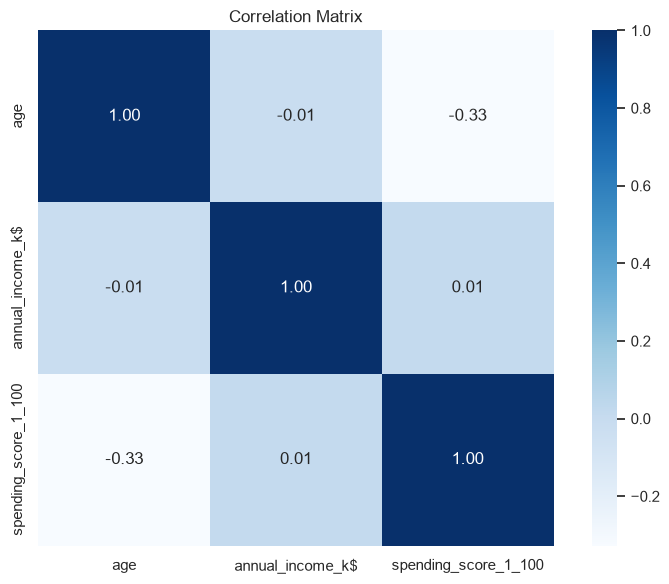

In [12]:
numeric_columns = [
    "age",
    "annual_income_k$",
    "spending_score_1_100"
]

correlation_matrix = df_clean[numeric_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    square=True
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "correlation_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()


## 8. Select Features for Customer Segmentation

For the main segmentation model, we use:
- **Annual Income (k$)**
- **Spending Score (1-100)**

These two variables provide a clear representation of purchasing capacity and customer engagement.


In [13]:
feature_columns = [
    "annual_income_k$",
    "spending_score_1_100"
]

X = df_clean[feature_columns].copy()

print("Features selected for clustering:")
display(X.head())

print("Feature shape:", X.shape)


Features selected for clustering:


,annual_income_k$,spending_score_1_100
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


Feature shape: (200, 2)


## 9. Visualize the Initial Customer Distribution

Before applying clustering, we visualize customers using income and spending score.


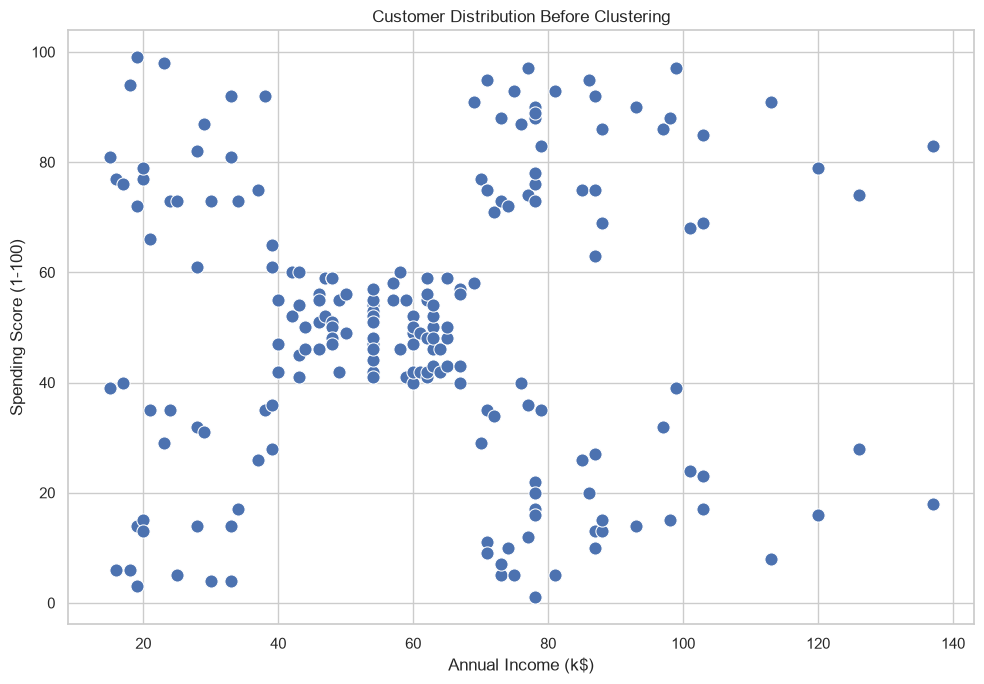

In [14]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_clean,
    x="annual_income_k$",
    y="spending_score_1_100",
    s=90
)

plt.title("Customer Distribution Before Clustering")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "customer_distribution_before_clustering.png"),
            dpi=300, bbox_inches="tight")
plt.show()


## 10. Feature Scaling

K-Means uses distances between observations. Scaling is therefore useful when features have different numerical ranges.

We standardize the two clustering features using `StandardScaler`.


In [15]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=feature_columns
)

display(X_scaled_df.head())


,annual_income_k$,spending_score_1_100
0,-1.74,-0.43
1,-1.74,1.20
2,-1.70,-1.72
3,-1.70,1.04
4,-1.66,-0.40


## 11. Determine the Optimal Number of Clusters — Elbow Method

The Elbow Method compares K-Means inertia for different values of `K`.

The selected K should balance model simplicity and within-cluster compactness.


In [16]:
inertia = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

elbow_results = pd.DataFrame({
    "Number of Clusters (K)": list(k_values),
    "Inertia": inertia
})

display(elbow_results)


,Number of Clusters (K),Inertia
0,1,400.00
1,2,269.69
2,3,157.70
3,4,108.92
4,5,65.57
5,6,55.06
6,7,44.86
7,8,37.23
8,9,32.39
9,10,29.98


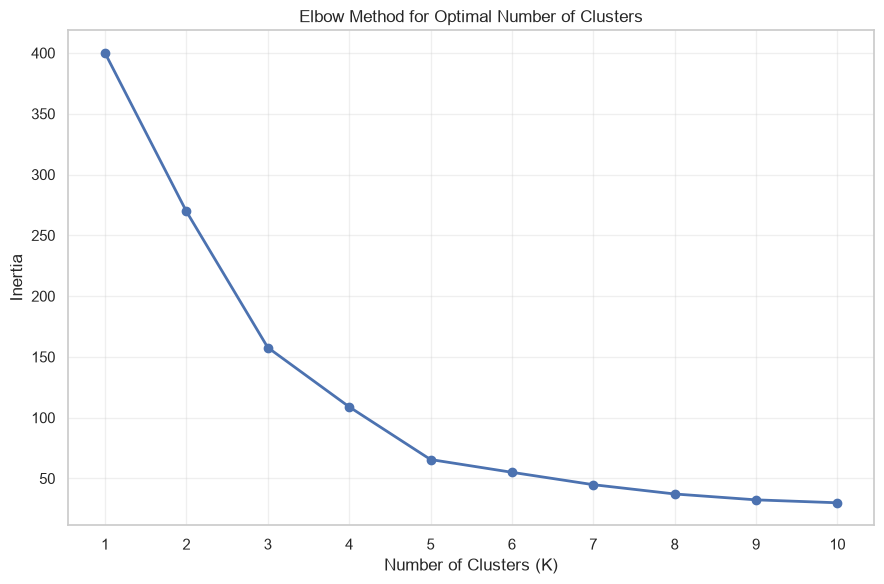

In [17]:
plt.figure(figsize=(9, 6))

plt.plot(
    k_values,
    inertia,
    marker="o",
    linewidth=2
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "elbow_curve.png"),
            dpi=300, bbox_inches="tight")
plt.show()


### Choosing K

For the standard Mall Customers dataset, **K = 5** is a commonly used and highly interpretable choice for income-spending segmentation.

The final model below uses five customer segments. The Elbow Method plot above should still be inspected as part of the project analysis.


In [18]:
OPTIMAL_K = 5

print(f"Selected number of clusters: K = {OPTIMAL_K}")


Selected number of clusters: K = 5


## 12. Train the Final K-Means Model

We now train K-Means with five clusters and assign a cluster label to every customer.


In [19]:
kmeans_final = KMeans(
    n_clusters=OPTIMAL_K,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_scaled)

df_segmented = df_clean.copy()
df_segmented["cluster"] = cluster_labels

print("K-Means clustering completed successfully.")
display(df_segmented.head(20))


K-Means clustering completed successfully.


,customerid,gender,age,annual_income_k$,spending_score_1_100,cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


## 13. Cluster Centers

The K-Means algorithm calculates a centroid for each cluster. We convert the standardized centroids back to the original income/spending scale so they are easier to interpret.


In [20]:
centers_scaled = kmeans_final.cluster_centers_

centers_original = scaler.inverse_transform(centers_scaled)

cluster_centers = pd.DataFrame(
    centers_original,
    columns=feature_columns
)

cluster_centers.index.name = "cluster"

display(cluster_centers.round(2))


,annual_income_k$,spending_score_1_100
cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


## 14. Final Customer Cluster Visualization

This is one of the key screenshots required for the internship evaluation.

The scatter plot shows customers grouped by their assigned K-Means cluster, with `X` markers representing cluster centers.


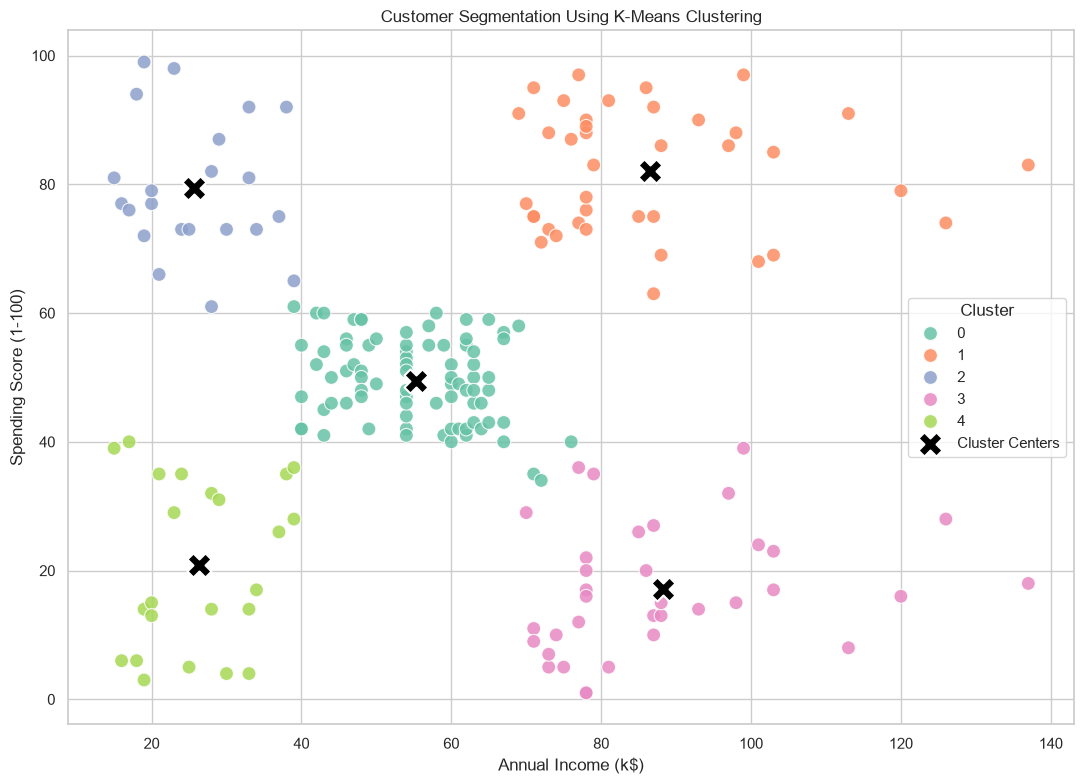

In [21]:
plt.figure(figsize=(11, 8))

sns.scatterplot(
    data=df_segmented,
    x="annual_income_k$",
    y="spending_score_1_100",
    hue="cluster",
    palette="Set2",
    s=100,
    alpha=0.85
)

plt.scatter(
    cluster_centers["annual_income_k$"],
    cluster_centers["spending_score_1_100"],
    marker="X",
    s=300,
    color="black",
    edgecolor="white",
    linewidth=1.5,
    label="Cluster Centers"
)

plt.title("Customer Segmentation Using K-Means Clustering")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "cluster_visualization.png"),
            dpi=300, bbox_inches="tight")
plt.show()


## 15. Cluster Distribution

We calculate how many customers belong to each segment.


In [22]:
cluster_counts = (
    df_segmented["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="customer_count")
)

cluster_counts["percentage"] = (
    cluster_counts["customer_count"]
    / len(df_segmented)
    * 100
)

display(cluster_counts.round(2))


,cluster,customer_count,percentage
0,0,81,40.50
1,1,39,19.50
2,2,22,11.00
3,3,35,17.50
4,4,23,11.50


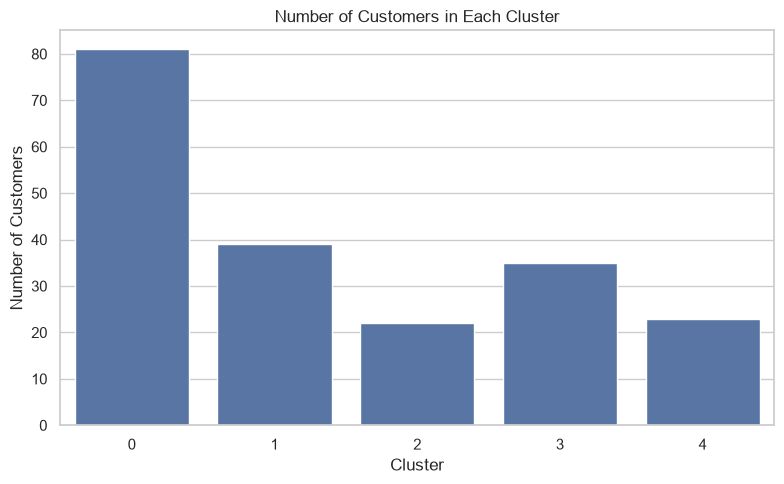

In [23]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=cluster_counts,
    x="cluster",
    y="customer_count"
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "cluster_distribution.png"),
            dpi=300, bbox_inches="tight")
plt.show()


## 16. Cluster Profiling

To interpret the clusters, calculate the average age, annual income, and spending score for every segment.


In [24]:
cluster_profile = (
    df_segmented
    .groupby("cluster")
    .agg(
        customer_count=("customerid", "count"),
        average_age=("age", "mean"),
        average_income=("annual_income_k$", "mean"),
        average_spending_score=("spending_score_1_100", "mean")
    )
    .round(2)
)

cluster_profile["customer_percentage"] = (
    cluster_profile["customer_count"]
    / len(df_segmented)
    * 100
).round(2)

display(cluster_profile)


,customer_count,average_age,average_income,average_spending_score,customer_percentage
cluster,,,,,
0,81,42.72,55.30,49.52,40.50
1,39,32.69,86.54,82.13,19.50
2,22,25.27,25.73,79.36,11.00
3,35,41.11,88.20,17.11,17.50
4,23,45.22,26.30,20.91,11.50


## 17. Cluster Statistics by Gender

Gender is not used as a clustering feature in the main model, but it can be examined after clustering to better understand the resulting customer segments.


In [25]:
gender_by_cluster = pd.crosstab(
    df_segmented["cluster"],
    df_segmented["gender"],
    normalize="index"
) * 100

display(gender_by_cluster.round(2))


gender,Female,Male
cluster,,
0,59.26,40.74
1,53.85,46.15
2,59.09,40.91
3,45.71,54.29
4,60.87,39.13


## 18. Automatic Cluster Interpretation

The following rule-based interpretation provides a simple business description based on each cluster's average income and spending score.

The labels are generated from the actual cluster centers, so they are not hard-coded to a particular cluster number.


In [26]:
overall_income_mean = df_segmented["annual_income_k$"].mean()
overall_spending_mean = df_segmented["spending_score_1_100"].mean()

def interpret_cluster(row):
    income = row["average_income"]
    spending = row["average_spending_score"]

    high_income = income >= overall_income_mean
    high_spending = spending >= overall_spending_mean

    if high_income and high_spending:
        return "High-Value Customers"
    elif high_income and not high_spending:
        return "High-Income Low-Spending Customers"
    elif not high_income and high_spending:
        return "Low/Moderate-Income High-Spending Customers"
    else:
        return "Low/Moderate-Income Low-Spending Customers"

business_profile = (
    cluster_profile
    .rename(columns={
        "average_income": "average_income",
        "average_spending_score": "average_spending_score"
    })
    .copy()
)

business_profile["segment_type"] = business_profile.apply(
    interpret_cluster,
    axis=1
)

display(business_profile)


,customer_count,average_age,average_income,average_spending_score,customer_percentage,segment_type
cluster,,,,,,
0,81,42.72,55.30,49.52,40.50,Low/Moderate-Income Low-Spending Customers
1,39,32.69,86.54,82.13,19.50,High-Value Customers
2,22,25.27,25.73,79.36,11.00,Low/Moderate-Income High-Spending Customers
3,35,41.11,88.20,17.11,17.50,High-Income Low-Spending Customers
4,23,45.22,26.30,20.91,11.50,Low/Moderate-Income Low-Spending Customers


## 19. Business Insights

### Example marketing strategies

The exact cluster characteristics should be taken from the `business_profile` table above.

- **High-Value Customers:** premium products, loyalty programs, exclusive offers, personalized recommendations.
- **High-Income Low-Spending Customers:** personalized promotions, product recommendations, introductory offers, and campaigns to increase engagement.
- **Low/Moderate-Income High-Spending Customers:** affordable premium options, loyalty rewards, bundles, and repeat-purchase campaigns.
- **Low/Moderate-Income Low-Spending Customers:** discounts, value products, seasonal offers, and cost-effective campaigns.

These insights demonstrate how clustering can support customer targeting and marketing decisions.


## 20. Optional Model Quality Check — Silhouette Score

The silhouette score measures how well-separated the clusters are. Values closer to 1 generally indicate better-defined clusters, while values around 0 indicate overlapping clusters.


In [27]:
silhouette = silhouette_score(X_scaled, cluster_labels)

print(f"Silhouette Score for K={OPTIMAL_K}: {silhouette:.4f}")


Silhouette Score for K=5: 0.5547


## 21. Save the Segmented Dataset

The final customer-level dataset includes the original information and the assigned cluster.


In [28]:
segmented_output_path = os.path.join(
    PROCESSED_DIR,
    "customer_segments.csv"
)

df_segmented.to_csv(segmented_output_path, index=False)

print("Segmented dataset saved to:")
print(segmented_output_path)


Segmented dataset saved to:
../data/processed\customer_segments.csv


## 22. Save Cluster Summary

Save the cluster-level business summary for use in the final report.


In [29]:
summary_output_path = os.path.join(
    OUTPUT_DIR,
    "cluster_summary.csv"
)

business_profile.to_csv(summary_output_path)

print("Cluster summary saved to:")
print(summary_output_path)


Cluster summary saved to:
../outputs\cluster_summary.csv


## 23. Save Cluster Centers

Cluster centers are also saved for documentation and further analysis.


In [30]:
centers_output_path = os.path.join(
    OUTPUT_DIR,
    "cluster_centers.csv"
)

cluster_centers.to_csv(centers_output_path)

print("Cluster centers saved to:")
print(centers_output_path)


Cluster centers saved to:
../outputs\cluster_centers.csv


## 24. Final Clustered Dataset

This output is useful for the required **Cluster Grouping/Output** screenshot.


In [31]:
display(
    df_segmented[
        [
            "customerid",
            "gender",
            "age",
            "annual_income_k$",
            "spending_score_1_100",
            "cluster"
        ]
    ].head(20)
)


,customerid,gender,age,annual_income_k$,spending_score_1_100,cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


## 25. Final Project Summary

The customer segmentation workflow is now complete.

### Completed Tasks

1. Loaded the Mall Customers dataset.
2. Inspected the dataset structure and quality.
3. Checked missing and duplicate values.
4. Cleaned and standardized the data.
5. Selected annual income and spending score as clustering features.
6. Standardized the clustering features.
7. Used the Elbow Method to study the suitable number of clusters.
8. Applied K-Means clustering with K=5.
9. Visualized customer segments and cluster centers.
10. Profiled each customer segment.
11. Calculated cluster distribution and silhouette score.
12. Generated business-oriented customer segment interpretations.
13. Saved the segmented dataset and cluster summaries.

### Mandatory Internship Screenshots

Capture screenshots of:
- **Dataset:** `df.head(10)`
- **Cluster Visualization:** `cluster_visualization.png`
- **Cluster Grouping/Output:** final clustered dataset containing the `cluster` column

Additional recommended screenshots:
- Dataset information
- Elbow Method curve
- Cluster profile table
- Silhouette score


## 26. Output Files

After running all cells, the project should contain files similar to:

```text
data/
└── processed/
    └── customer_segments.csv

outputs/
├── age_distribution.png
├── income_distribution.png
├── spending_score_distribution.png
├── correlation_matrix.png
├── customer_distribution_before_clustering.png
├── elbow_curve.png
├── cluster_visualization.png
├── cluster_distribution.png
├── cluster_summary.csv
└── cluster_centers.csv
```

These outputs can be used in the final internship PDF report.
